In [1]:
from utilities import load_dat
from numpy.random import normal, choice
from scipy.stats import spearmanr
from scipy import stats
plt.rcParams["font.family"] = "serif"
import labels as l
import os
from tqdm import tqdm

def histogram(array):
    return np.histogram(array, bins=np.logspace(np.log10(min(array)), np.log10(max(array)), 60))

In [2]:
npz_filename = 'bav_estimates.npz'
if npz_filename not in os.listdir():
    fit = np.load('alpha.npz')
    dat = load_dat('pulsars.dat', verbose=False)

    alpha_arr = np.ravel(fit['alpha'])
    alpha_arr = alpha_arr[alpha_arr!=0]

    alpha_arr_gaens = np.ravel(fit['alpha'][fit['M'] <= 2])
    alpha_arr_gaens = alpha_arr_gaens[alpha_arr_gaens!=0]

    n_sample = 10000
    kappa = 0.812
    ind_dat = np.abs(dat.GB) < 5

    rho_ = []
    bav_model = []
    bav_naive = []
    bav_gaens = []
    for j in tqdm(range(n_sample)):
        DM = normal(dat.DM[ind_dat], dat.DM_err[ind_dat])
        if np.sum(DM<0):    continue

        RM = normal(dat.RM[ind_dat], dat.RM_err[ind_dat])
        rho = spearmanr(np.abs(RM), DM)[0]
        rho_.append(rho)

        alpha = choice(alpha_arr)
        alpha_g = choice(alpha_arr_gaens)

        bav_naive_ = 1/kappa*RM/DM
        bav_model_ = 1/alpha*bav_naive_
        bav_gaens_ = 1/alpha_g*bav_naive_

        bav_naive.extend(bav_naive_)
        bav_model.extend(bav_model_)
        bav_gaens.extend(bav_gaens_)

    bav_naive = np.sort(np.abs(bav_naive))
    bav_model = np.sort(np.abs(bav_model))
    bav_gaens = np.sort(np.abs(bav_gaens))

    np.savez(npz_filename, bav_naive=bav_naive, bav_model=bav_model, bav_gaens=bav_gaens)
else:
    estimates = np.load(npz_filename)
    bav_naive = estimates['bav_naive']
    bav_model = estimates['bav_model']
    bav_gaens = estimates['bav_gaens']

In [3]:
n0, bins0 = histogram(bav_naive)
n1, bins1 = histogram(bav_model)
n2, bins2 = histogram(bav_gaens)

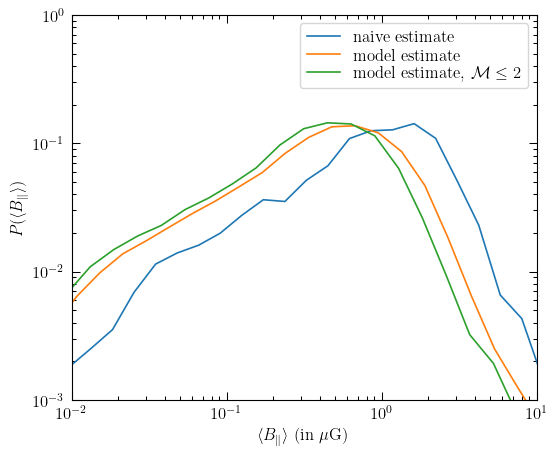

In [4]:
plt.figure(figsize=(6,5))
plt.plot((bins0[1:]+bins0[:-1])/2, n0/len(bav_naive), label='naive estimate')
plt.plot((bins1[1:]+bins1[:-1])/2, n1/len(bav_model), label='model estimate')
plt.plot((bins2[1:]+bins2[:-1])/2, n2/len(bav_gaens), label=r'model estimate, $%s \leq 2$'%l.mach)
plt.xlim(0.01, 10)
plt.ylim(1e-3, 1)
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$%s$ (in $\mu$G)'%l.bav)
plt.ylabel('$P(%s)$'%l.bav)
plt.legend()
plt.savefig('mag_estimates.png')
plt.savefig('mag_estimates.pdf')